In [23]:
!source .venv/bin/activate

In [24]:
# Load the CSV and display the first five rows

In [25]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = SparkSession.builder \
    .appName("AmazonReviewsAnalysis") \
    .getOrCreate()

df = spark.read.csv(
    "Reviews.csv",
    header=True,
    inferSchema=True
)

df.show(5, truncate=50)

+---+----------+--------------+-----------------------------------+--------------------+----------------------+-----+----------+-------------------------+--------------------------------------------------+
| Id| ProductId|        UserId|                        ProfileName|HelpfulnessNumerator|HelpfulnessDenominator|Score|      Time|                  Summary|                                              Text|
+---+----------+--------------+-----------------------------------+--------------------+----------------------+-----+----------+-------------------------+--------------------------------------------------+
|  1|B001E4KFG0|A3SGXH7AUHU8GW|                         delmartian|                   1|                     1|    5|1303862400|    Good Quality Dog Food|I have bought several of the Vitality canned do...|
|  2|B00813GRG4|A1D87F6ZCVE5NK|                             dll pa|                   0|                     0|    1|1346976000|        Not as Advertised|"Product arrived label

In [26]:
# Count reviews, unique products, and unique users

In [27]:
df.select(
    F.count("Id").alias("TotalReviews"),
    F.countDistinct("ProductId").alias("UniqueProducts"),
    F.countDistinct("UserId").alias("UniqueUsers")
).show()

[Stage 36:====>                                                   (1 + 11) / 12]

+------------+--------------+-----------+
|TotalReviews|UniqueProducts|UniqueUsers|
+------------+--------------+-----------+
|      568454|         74258|     256059|
+------------+--------------+-----------+



In [28]:
# Count reviews per product and find the most-reviewed product

In [50]:
product_counts = (
    df.groupBy("ProductId")
      .count()
      .orderBy(F.desc("count"))
)

product_counts.show(5)

product_counts.first()["ProductId"]

+----------+-----+
| ProductId|count|
+----------+-----+
|B007JFMH8M|  913|
|B002QWP89S|  632|
|B0026RQTGE|  632|
|B002QWHJOU|  632|
|B002QWP8H0|  632|
+----------+-----+
only showing top 5 rows


'B007JFMH8M'

/home/bytejoseph/pyspark-project/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/bytejoseph/pyspark-project/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


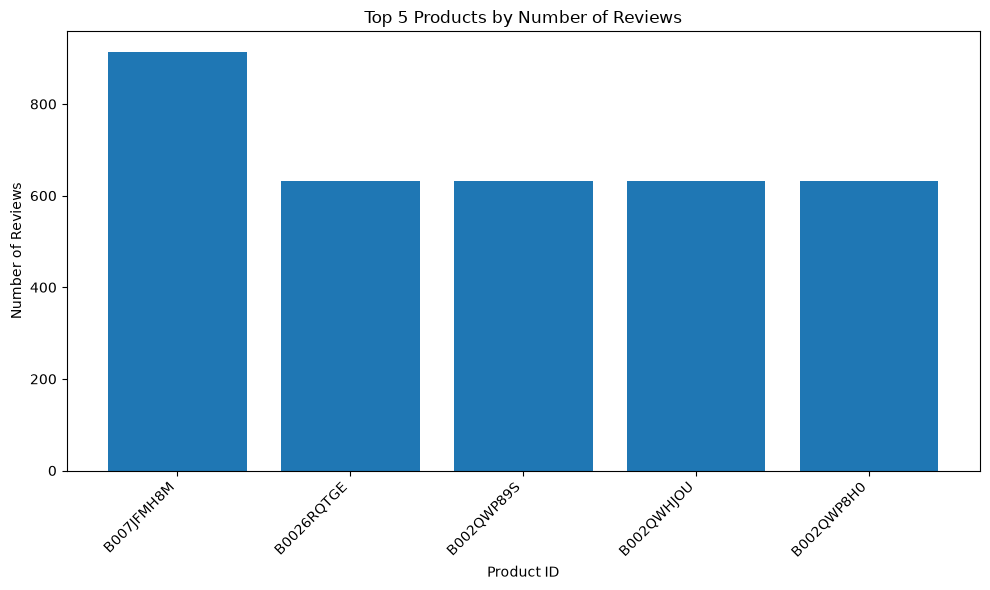

In [51]:
top_5_products = product_counts.limit(5)

# Convert only the top 5 rows to Pandas
plot_df = top_5_products.toPandas()

# Create bar chart
plt.figure(figsize=(10, 6))

plt.bar(
    plot_df["ProductId"],
    plot_df["count"]
)

plt.title("Top 5 Products by Number of Reviews")
plt.xlabel("Product ID")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [32]:
# Find profile names for a specific user

In [54]:
user_id = "A3OXHLG6DIBRW8"

def fetch_name(df, user_id):
    result = (
        df.filter(F.col("UserId") == user_id)
          .select("ProfileName")
          .first()
    )

    return result["ProfileName"] if result else None

# Call the function
name = fetch_name(df, user_id)
print(name)

"C. F. Hill ""CFH"""


In [30]:
# Count reviews per user

In [31]:
user_counts = (
    df.groupBy("UserId")
      .count()
      .orderBy(F.desc("count"))
)

user_counts.show(5)

print(user_counts.first()["UserId"])

+--------------+-----+
|        UserId|count|
+--------------+-----+
|A3OXHLG6DIBRW8|  448|
|A1YUL9PCJR3JTY|  421|
| AY12DBB0U420B|  389|
|A281NPSIMI1C2R|  365|
|A1Z54EM24Y40LL|  256|
+--------------+-----+
only showing top 5 rows
A3OXHLG6DIBRW8


/home/bytejoseph/pyspark-project/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/bytejoseph/pyspark-project/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


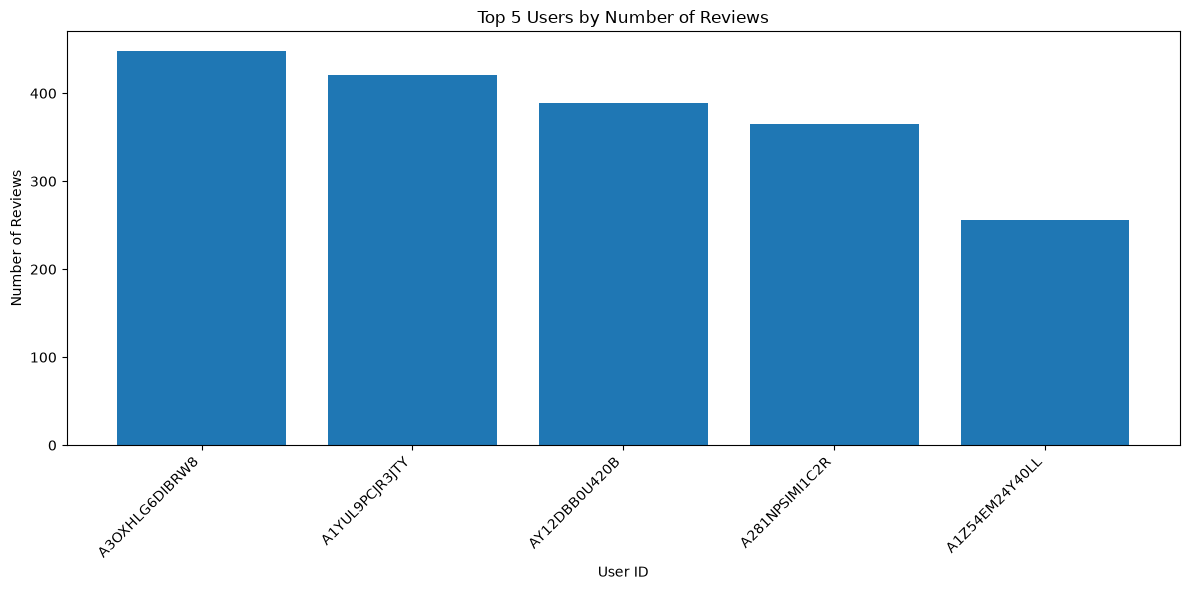

In [52]:
top_5_users = user_counts.limit(5)
plot_df = top_5_users.toPandas()

# Plot bar chart
plt.figure(figsize=(12, 6))

plt.bar(
    plot_df["UserId"],
    plot_df["count"]
)

plt.title("Top 5 Users by Number of Reviews")
plt.xlabel("User ID")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [34]:
# Find the top five most-reviewed products

In [35]:
df.groupBy("ProductId") \
  .count() \
  .orderBy(F.desc("count")) \
  .show(5)

+----------+-----+
| ProductId|count|
+----------+-----+
|B007JFMH8M|  913|
|B002QWP89S|  632|
|B0026RQTGE|  632|
|B002QWHJOU|  632|
|B002QWP8H0|  632|
+----------+-----+
only showing top 5 rows


In [36]:
# Find the top five most-active users

In [37]:
top_5_users = (
    df.groupBy("UserId")
      .agg(
          F.count("Id").alias("ReviewCount"),
          F.first("ProfileName", ignorenulls=True).alias("ProfileName")
      )
      .orderBy(F.desc("ReviewCount"))
      .limit(5)
)

top_5_users.show(truncate=False)

[Stage 58:======================================>                  (8 + 4) / 12]

+--------------+-----------+------------------------------------------+
|UserId        |ReviewCount|ProfileName                               |
+--------------+-----------+------------------------------------------+
|A3OXHLG6DIBRW8|448        |"C. F. Hill ""CFH"""                      |
|A1YUL9PCJR3JTY|421        |"O. Brown ""Ms. O. Khannah-Brown"""       |
|AY12DBB0U420B |389        |Gary Peterson                             |
|A281NPSIMI1C2R|365        |"Rebecca of Amazon ""The Rebecca Review"""|
|A1Z54EM24Y40LL|256        |c2                                        |
+--------------+-----------+------------------------------------------+



In [38]:
# Find the top three users whose reviews received the most helpful votes

In [39]:


# Clean the numeric columns
df_clean = (
    df.withColumn(
        "HelpfulnessNumerator",
        F.expr("try_cast(trim(HelpfulnessNumerator) AS DOUBLE)")
    )
    .withColumn(
        "HelpfulnessDenominator",
        F.expr("try_cast(trim(HelpfulnessDenominator) AS DOUBLE)")
    )
)

# Find the top 3 most helpful reviewers
top_3_helpful = (
    df_clean
    .groupBy("UserId", "ProfileName")
    .agg(
        F.sum("HelpfulnessNumerator").alias("TotalHelpful"),
        F.sum("HelpfulnessDenominator").alias("TotalVotes"),
        F.count("Id").alias("ReviewCount")
    )
    .orderBy(F.desc("TotalHelpful"))
    .limit(3)
)

top_3_helpful.show(truncate=False)

[Stage 61:===================>                                     (4 + 8) / 12]

+--------------+----------------------------------+------------+----------+-----------+
|UserId        |ProfileName                       |TotalHelpful|TotalVotes|ReviewCount|
+--------------+----------------------------------+------------+----------+-----------+
|A1B4MIXYVIKMU2|"D. Truong ""Duke of New Mexico"""|5594.0      |5629.0    |23         |
|A10PV6AP8SXEDI|J. Goldman                        |4720.0      |4770.0    |10         |
|A32WS1SQTDYYO |"G. Roberti ""Lube Man"""         |3648.0      |3712.0    |13         |
+--------------+----------------------------------+------------+----------+-----------+



In [40]:
# Find the top three products with the most five-star reviews

In [42]:
positive_reviews = df.filter(
    F.expr("try_cast(trim(Score) AS INT)") == 5
)

positive_reviews.groupBy("ProductId") \
    .count() \
    .orderBy(F.desc("count")) \
    .show(3, truncate=False)

+----------+-----+
|ProductId |count|
+----------+-----+
|B007JFMH8M|624  |
|B003B3OOPA|517  |
|B000NMJWZO|501  |
+----------+-----+
only showing top 3 rows


In [ ]:
# Find the top three users with the most negative reviews

In [43]:
negative_reviews = df.filter(
    F.expr("try_cast(trim(Score) AS INT)") == 1
)

top_3_negative = (
    negative_reviews
    .groupBy("UserId", "ProfileName")
    .count()
    .orderBy(F.desc("count"))
    .limit(3)
)

top_3_negative.show(truncate=False)

+--------------+-----------------+-----+
|UserId        |ProfileName      |count|
+--------------+-----------------+-----+
|A3TVZM3ZIXG8YW|christopher hayes|199  |
|AKZKG2Z7CNV27 |BreezyPaige      |67   |
|AMQ1MEG334SAP |Bigmac           |47   |
+--------------+-----------------+-----+



In [ ]:
# Find top 5 products By review growth over time

In [45]:


from pyspark.sql.window import Window

# Safely convert Unix timestamps and create dates
df_clean = (
    df.withColumn(
        "TimeLong",
        F.expr("try_cast(trim(Time) AS BIGINT)")
    )
    .withColumn(
        "Date",
        F.to_date(F.from_unixtime(F.col("TimeLong")))
    )
    .filter(F.col("Date").isNotNull())
)

# Count reviews per product per month
monthly = (
    df_clean
    .withColumn("Month", F.date_trunc("month", F.col("Date")))
    .groupBy("ProductId", "Month")
    .agg(F.count("*").alias("Reviews"))
)

# Rank monthly records for each product
w = Window.partitionBy("ProductId").orderBy("Month")

monthly_ranked = (
    monthly
    .withColumn("MonthRank", F.row_number().over(w))
    .withColumn(
        "TotalMonths",
        F.count("*").over(Window.partitionBy("ProductId"))
    )
)

# Split monthly records into first and second halves
monthly_split = monthly_ranked.withColumn(
    "Half",
    F.when(
        F.col("MonthRank") <= F.floor(F.col("TotalMonths") / 2),
        F.lit("First")
    ).otherwise(F.lit("Second"))
)

# Calculate review growth
growth_df = (
    monthly_split
    .filter(F.col("TotalMonths") >= 2)
    .groupBy("ProductId")
    .agg(
        F.sum(
            F.when(F.col("Half") == "First", F.col("Reviews"))
             .otherwise(0)
        ).alias("FirstHalfReviews"),
        F.sum(
            F.when(F.col("Half") == "Second", F.col("Reviews"))
             .otherwise(0)
        ).alias("SecondHalfReviews")
    )
    .withColumn(
        "Growth",
        F.col("SecondHalfReviews") - F.col("FirstHalfReviews")
    )
    .withColumn(
        "GrowthPercent",
        F.when(
            F.col("FirstHalfReviews") > 0,
            F.col("Growth") / F.col("FirstHalfReviews") * 100
        )
    )
)

# Show the top 5 products by absolute review increase
top_products = (
    growth_df
    .orderBy(F.desc("Growth"))
    .limit(5)
)

top_products.show(truncate=False)


[Stage 72:====>                                                   (1 + 11) / 12]

+----------+----------------+-----------------+------+------------------+
|ProductId |FirstHalfReviews|SecondHalfReviews|Growth|GrowthPercent     |
+----------+----------------+-----------------+------+------------------+
|B003B3OOPA|52              |571              |519   |998.076923076923  |
|B002LANN56|15              |449              |434   |2893.3333333333335|
|B002QWHJOU|114             |518              |404   |354.3859649122807 |
|B002QWP89S|114             |518              |404   |354.3859649122807 |
|B002QWP8H0|114             |518              |404   |354.3859649122807 |
+----------+----------------+-----------------+------+------------------+



In [ ]:
# Filter reviews by user, convert Unix timestamps to dates, and sort

In [46]:
user_id = "A3OXHLG6DIBRW8"

user_purchases = (
    df.filter(F.col("UserId") == user_id)
      .withColumn(
          "Date",
          F.to_date(F.from_unixtime(F.col("Time").cast("long")))
      )
      .orderBy("Date")
      .select(
          "UserId",
          "ProductId",
          "ProfileName",
          "Date",
          "Score",
          "Summary"
      )
)

user_purchases.show(500, truncate=False)

+--------------+----------+--------------------+----------+-----+------------------------------------------------------------------------+
|UserId        |ProductId |ProfileName         |Date      |Score|Summary                                                                 |
+--------------+----------+--------------------+----------+-----+------------------------------------------------------------------------+
|A3OXHLG6DIBRW8|B000Z978SS|"C. F. Hill ""CFH"""|2008-10-17|4    |Really Good Sugar Substitute - Highly Recommended!                      |
|A3OXHLG6DIBRW8|B000UPALKO|"C. F. Hill ""CFH"""|2008-10-28|5    |Great Tasting Protein Mix - Recommended                                 |
|A3OXHLG6DIBRW8|B000UPALJ0|"C. F. Hill ""CFH"""|2008-10-28|5    |Great Tasting Protein Mix - Recommended                                 |
|A3OXHLG6DIBRW8|B001G8W7YC|"C. F. Hill ""CFH"""|2008-11-01|5    |Chewable Caffeine Goodness - Recommended!                               |
|A3OXHLG6DIBRW8|B0008JF9FY|